# 01. Khám phá dữ liệu (EDA) và tiền xử lý ảnh cho nhánh thị giác

**Dự án:** Phân loại độ chín sầu riêng bằng chưng cất tri thức đa phương thức (Cross-Modal Knowledge Distillation - CMKD)
**Phụ trách:** Member 1 (Vision Lead)
**Tài liệu tham chiếu:** `README.md` (đặc tả dataset) và `specification/Đặc tả đề tài.pdf` (mục 1.3.1 - nhánh thị giác)

---

### Mục tiêu của notebook

Notebook là nơi khảo sát dữ liệu ảnh và **thực nghiệm, kiểm chứng toàn bộ các bước tiền xử lý**. Sau khi các bước đã chạy ổn định ở đây, class `VisionPreprocessor` được sao chép nguyên vẹn sang module [preprocess_vision.py](preprocess_vision.py) để các notebook huấn luyện phía sau import và tái sử dụng.

### Cấu trúc notebook

| Phần | Nội dung |
| :--- | :--- |
| 1 | Cài đặt thư viện, import và cấu hình chung |
| 2 | Kết nối Google Drive, khai báo đường dẫn và kiểm tra dữ liệu |
| 3 | Phân bố nhãn độ chín, phân chia train/val/test và tương quan với chỉ số lý hóa |
| 4 | Khảo sát 6 góc chụp và độ đầy đủ ảnh của từng quả |
| 5 | Chất lượng ảnh: độ phân giải, độ sáng, màu sắc, độ sắc nét |
| 6 | Tiền xử lý và làm giàu dữ liệu: CLAHE, augmentation theo mức, Mixup/CutMix |
| 7 | Đóng gói PyTorch Dataset và DataLoader |
| 8 | Kết luận và bàn giao |

> ⚠️ **Nguyên tắc an toàn dữ liệu:** Notebook chỉ đọc dữ liệu trong `data/raw/` và `data/split_data/`. Mọi bước xử lý đều thực hiện trên RAM, không ghi đè hay sửa đổi dữ liệu gốc.

## 1. Cài đặt thư viện và cấu hình chung

In [71]:
# Cài đặt các thư viện còn thiếu (chủ yếu cần khi chạy trên Colab)
import importlib.util
import subprocess
import sys

REQUIRED_PACKAGES = {  # Tên gói pip -> tên module khi import
    "opencv-python": "cv2",
    "pillow": "PIL",
    "torch": "torch",
    "torchvision": "torchvision",
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "tqdm": "tqdm",
}

missing_packages = [pkg for pkg, module in REQUIRED_PACKAGES.items() if importlib.util.find_spec(module) is None]
if missing_packages:
    print(f"Đang cài đặt các gói còn thiếu: {', '.join(missing_packages)}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing_packages])

print("✅ Đã sẵn sàng đầy đủ thư viện.")

✅ Đã sẵn sàng đầy đủ thư viện.


In [72]:
# Import thư viện, cố định random seed và khai báo các hằng số dùng chung
import glob
import os
import random
import re
import warnings
from typing import Dict, List, Optional, Sequence, Tuple, Union

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torchvision.transforms as transforms
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore")

# Cố định random seed để kết quả có thể tái lập
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Cấu hình hiển thị đồ thị
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "sans-serif"]
plt.rcParams["axes.unicode_minus"] = False

# Hằng số dùng chung cho toàn notebook
RIPENESS_ORDER = ["Unripe", "Ripe", "Overripe"]
RIPENESS_PALETTE = {"Unripe": "#2ecc71", "Ripe": "#f39c12", "Overripe": "#e74c3c", "Unknown": "gray"}
LABEL_TO_IDX = {name: idx for idx, name in enumerate(RIPENESS_ORDER)}
IDX_TO_LABEL = {idx: name for name, idx in LABEL_TO_IDX.items()}
ORIENTATIONS = ["TOP", "BOT", "SA", "SB", "SC", "SD"]
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")


def list_images(folder: str) -> List[str]:
    """Liệt kê ảnh trong thư mục, không phân biệt hoa thường và không bị trùng lặp trên Windows."""
    if not os.path.isdir(folder):
        return []
    return sorted(
        os.path.join(folder, name)
        for name in os.listdir(folder)
        if name.lower().endswith(IMAGE_EXTENSIONS)
    )


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Thiết bị tính toán: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
else:
    print("⚠️ Đang chạy trên CPU, nên bật GPU trên Colab nếu cần xử lý nhiều ảnh.")

Thiết bị tính toán: cpu
⚠️ Đang chạy trên CPU, nên bật GPU trên Colab nếu cần xử lý nhiều ảnh.


## 2. Kết nối Google Drive và kiểm tra dữ liệu

Dữ liệu được lưu trên Google Drive theo `README.md`:
- Thư mục `data/raw/`: [Drive link](https://drive.google.com/drive/folders/1gIhGj-txv1ZF_RfslbAh7bagNZdnIRhL?usp=drive_link)
- Thư mục `data/split_data/`: [Drive link](https://drive.google.com/drive/folders/1ro-ETqoDNCuDwbYdZkvDuztLAF5B0XTC?usp=drive_link)

Cell bên dưới thực hiện:
1. Tự động mount Google Drive khi chạy trên Colab.
2. Khai báo đường dẫn `DATA_RAW_DIR` và `DATA_SPLIT_DIR`, bạn chỉ cần sửa hai biến này nếu dữ liệu nằm ở vị trí khác.
3. Kiểm tra ngay toàn bộ file và thư mục bắt buộc; nếu thiếu sẽ dừng và liệt kê đầy đủ các mục còn thiếu.
4. Nếu thư mục ảnh đang rỗng (ví dụ chạy thử trên máy cục bộ), tạo một bộ ảnh mô phỏng nhỏ trong thư mục cache tạm để các cell phía sau vẫn chạy được.

In [73]:
# 2.1. Mount Google Drive khi chạy trên Colab
IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")

if IN_COLAB:
    from google.colab import drive

    if not os.path.exists("/content/drive/MyDrive"):
        drive.mount("/content/drive")
    print("✅ Google Drive đã được kết nối tại /content/drive")
else:
    print("Đang chạy trên máy cục bộ.")

# 2.2. Khai báo đường dẫn dữ liệu (sửa tại đây nếu dữ liệu nằm ở vị trí khác)
if IN_COLAB:
    DATA_RAW_DIR = "/content/drive/MyDrive/durian-ripeness-cmkd/data/raw"
    DATA_SPLIT_DIR = "/content/drive/MyDrive/durian-ripeness-cmkd/data/split_data"
    DEMO_CACHE_DIR = "/content/colab_temp_cache/demo_vision_samples"
else:
    DATA_RAW_DIR = os.path.abspath("../../../data/raw")
    DATA_SPLIT_DIR = os.path.abspath("../../../data/split_data")
    DEMO_CACHE_DIR = os.path.abspath("demo_vision_samples")

CSV_RAW_PATH = os.path.join(DATA_RAW_DIR, "durian_characteristics_cleaned.csv")
CSV_SPLIT_MAPPING = os.path.join(DATA_SPLIT_DIR, "sample_split_mapping.csv")
RGB_RAW_DIR = os.path.join(DATA_RAW_DIR, "dataset_clean_rgb")

# 2.3. Kiểm tra các file và thư mục bắt buộc
required_items = [
    ("Thư mục raw data", DATA_RAW_DIR, os.path.isdir),
    ("Thư mục split data", DATA_SPLIT_DIR, os.path.isdir),
    ("File bảng đặc tính", CSV_RAW_PATH, os.path.isfile),
    ("File phân chia mẫu", CSV_SPLIT_MAPPING, os.path.isfile),
    ("Thư mục ảnh RGB", RGB_RAW_DIR, os.path.isdir),
]

print("\nKiểm tra đường dẫn dữ liệu:")
missing_items = []
for name, path, check in required_items:
    ok = check(path)
    print(f"  {'✅' if ok else '❌'} {name:<20}: {path}")
    if not ok:
        missing_items.append(name)

if missing_items:
    raise FileNotFoundError(
        f"Thiếu {len(missing_items)} mục bắt buộc: {', '.join(missing_items)}. "
        "Hãy kiểm tra Google Drive đã mount chưa và sửa lại DATA_RAW_DIR / DATA_SPLIT_DIR."
    )


# 2.4. Quét ảnh thật, nếu chưa có thì tạo bộ ảnh mô phỏng trong cache tạm
def create_demo_images(folder: str) -> None:
    """Tạo ảnh mô phỏng quả sầu riêng (hình elip có gai) đặt tên theo đúng quy ước của dataset."""
    os.makedirs(folder, exist_ok=True)
    demo_fruits = [  # (sample_id, maturity, class, ripeness, màu vỏ RGB)
        (1, "Immature", "A", "Unripe", (70, 140, 50)),
        (8, "Immature", "A", "Ripe", (130, 160, 45)),
        (15, "Immature", "A", "Overripe", (165, 145, 55)),
        (45, "Mature", "B", "Ripe", (140, 170, 50)),
    ]
    height, width = 400, 600  # Giữ tỷ lệ 3:2 giống ảnh thật
    center = (width // 2, height // 2)

    for sample_id, maturity, cls, ripeness, color in demo_fruits:
        for orientation in ORIENTATIONS:
            path = os.path.join(folder, f"durian_{sample_id:03d}_{maturity}_{cls}_{ripeness}_{orientation}.jpg")
            if os.path.exists(path):
                continue
            canvas = np.full((height, width, 3), (235, 235, 230), dtype=np.uint8)
            axes = (150, 150) if orientation in ("TOP", "BOT") else (140, 170)
            cv2.ellipse(canvas, center, axes, 0, 0, 360, color, -1)

            rng = np.random.RandomState(sample_id * 100 + ord(orientation[0]))
            for _ in range(300):  # Vẽ gai
                pt = (rng.randint(center[0] - 130, center[0] + 130), rng.randint(center[1] - 160, center[1] + 160))
                if ((pt[0] - center[0]) / axes[0]) ** 2 + ((pt[1] - center[1]) / axes[1]) ** 2 < 0.85:
                    spike = tuple(int(np.clip(c + rng.randint(-30, 30), 0, 255)) for c in color)
                    cv2.circle(canvas, pt, rng.randint(3, 8), spike, -1)
            if orientation == "TOP":  # Vẽ cuống
                cv2.circle(canvas, center, 30, (70, 50, 30), -1)
            cv2.imwrite(path, cv2.cvtColor(canvas, cv2.COLOR_RGB2BGR))


real_images = list_images(RGB_RAW_DIR)
if real_images:
    ACTIVE_IMAGE_DIR = RGB_RAW_DIR
    print(f"\n✅ Sử dụng {len(real_images)} ảnh thật từ: {ACTIVE_IMAGE_DIR}")
else:
    create_demo_images(DEMO_CACHE_DIR)
    ACTIVE_IMAGE_DIR = DEMO_CACHE_DIR
    print(f"\n⚠️ Thư mục ảnh thật đang rỗng, chuyển sang dùng ảnh mô phỏng tại: {ACTIVE_IMAGE_DIR}")
    print("   Các số liệu thống kê ảnh bên dưới chỉ mang tính minh họa.")

✅ Google Drive đã được kết nối tại /content/drive

Kiểm tra đường dẫn dữ liệu:
  ✅ Thư mục raw data    : /content/drive/MyDrive/durian-ripeness-cmkd/data/raw
  ✅ Thư mục split data  : /content/drive/MyDrive/durian-ripeness-cmkd/data/split_data
  ✅ File bảng đặc tính  : /content/drive/MyDrive/durian-ripeness-cmkd/data/raw/durian_characteristics_cleaned.csv
  ✅ File phân chia mẫu  : /content/drive/MyDrive/durian-ripeness-cmkd/data/split_data/sample_split_mapping.csv
  ✅ Thư mục ảnh RGB     : /content/drive/MyDrive/durian-ripeness-cmkd/data/raw/dataset_clean_rgb

✅ Sử dụng 2718 ảnh thật từ: /content/drive/MyDrive/durian-ripeness-cmkd/data/raw/dataset_clean_rgb


## 3. Phân bố nhãn độ chín và phân chia dữ liệu

Bài toán phân loại 3 trạng thái độ chín (`Ripeness`):
- `Unripe`: chưa chín, cơm cứng, chưa có mùi thơm.
- `Ripe`: chín tối ưu, đạt chuẩn thương phẩm, cơm mềm ngọt, rãnh gai nở.
- `Overripe`: chín quá, cơm nhũn, vỏ có thể nứt, mùi lên men.

Dữ liệu gồm 189 quả, được chia theo **cấp độ quả** (sample-level): mọi ảnh của cùng một quả chỉ thuộc duy nhất một tập train, val hoặc test, tránh rò rỉ dữ liệu giữa các tập.

Bảng đặc tính: 189 quả | bảng split: 189 quả

Phân bố nhãn độ chín:
  Unripe   :  63 quả (33.3%)
  Ripe     :  63 quả (33.3%)
  Overripe :  63 quả (33.3%)

Phân bố nhãn theo từng tập:


Ripeness,Unripe,Ripe,Overripe,All
Split,,,,
test,10,10,9,29
train,44,44,44,132
val,9,9,10,28
All,63,63,63,189


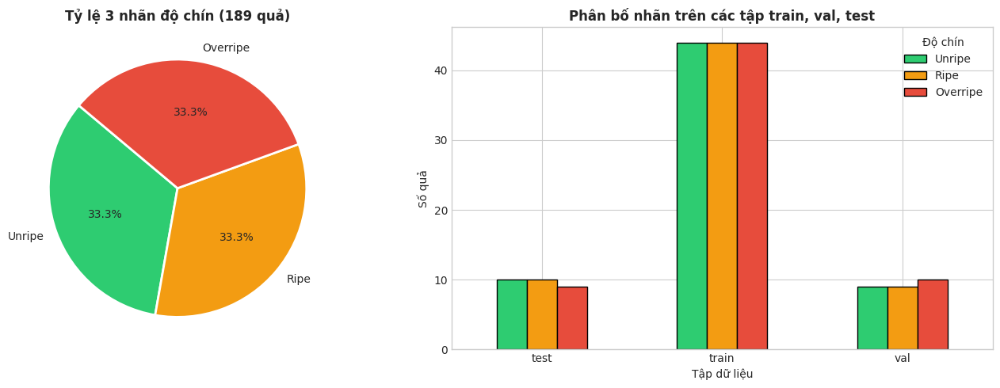

In [74]:
# 3.1. Đọc bảng đặc tính, gộp thông tin split và thống kê phân bố nhãn
df_char = pd.read_csv(CSV_RAW_PATH)
df_split = pd.read_csv(CSV_SPLIT_MAPPING)
print(f"Bảng đặc tính: {len(df_char)} quả | bảng split: {len(df_split)} quả")

if "sample_id" not in df_char.columns:
    df_char["sample_id"] = df_char["Replicate"].astype(str).str.extract(r"(\d+)")[0].astype(int)

df_merged = df_char.merge(df_split[["sample_id", "Split"]], on="sample_id", how="left")

ripeness_counts = df_merged["Ripeness"].value_counts().reindex(RIPENESS_ORDER)
print("\nPhân bố nhãn độ chín:")
for name, count in ripeness_counts.items():
    print(f"  {name:<9}: {count:>3} quả ({count / len(df_merged):.1%})")

print("\nPhân bố nhãn theo từng tập:")
display(pd.crosstab(df_merged["Split"], df_merged["Ripeness"], margins=True)[RIPENESS_ORDER + ["All"]])

colors = [RIPENESS_PALETTE[name] for name in RIPENESS_ORDER]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].pie(
    ripeness_counts, labels=ripeness_counts.index, autopct="%1.1f%%", startangle=140,
    colors=colors, wedgeprops={"edgecolor": "white", "linewidth": 2},
)
axes[0].set_title(f"Tỷ lệ 3 nhãn độ chín ({len(df_merged)} quả)", fontweight="bold")

pd.crosstab(df_merged["Split"], df_merged["Ripeness"])[RIPENESS_ORDER].plot(
    kind="bar", ax=axes[1], color=colors, edgecolor="black", rot=0,
)
axes[1].set_title("Phân bố nhãn trên các tập train, val, test", fontweight="bold")
axes[1].set_xlabel("Tập dữ liệu")
axes[1].set_ylabel("Số quả")
axes[1].legend(title="Độ chín")

plt.tight_layout()
plt.show()

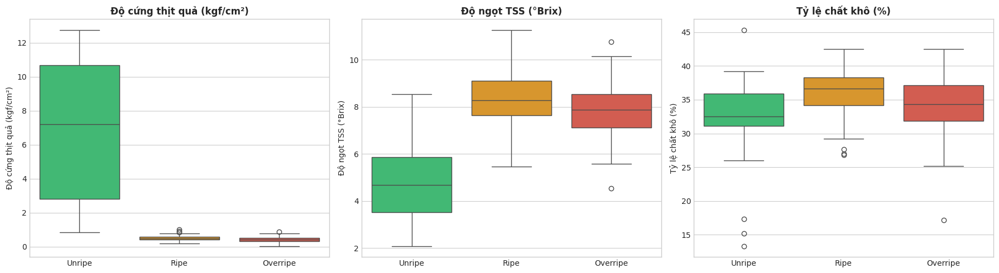

Trung vị các chỉ số theo độ chín:


,Firmness_AVE,TSS_AVE,Dry_Matter_AVE
Ripeness,,,
Unripe,7.22,4.67,32.50
Ripe,0.49,8.27,36.67
Overripe,0.43,7.88,34.33


Nhận xét: từ Unripe sang Ripe, độ cứng giảm từ 7.22 xuống 0.49 kgf/cm² (khoảng 14.7 lần), TSS tăng từ 4.67 lên 8.27 °Brix.


In [75]:
# 3.2. Tương quan giữa nhãn độ chín và các chỉ số lý hóa
physico_cols = {
    "Firmness_AVE": "Độ cứng thịt quả (kgf/cm²)",
    "TSS_AVE": "Độ ngọt TSS (°Brix)",
    "Dry_Matter_AVE": "Tỷ lệ chất khô (%)",
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (col, label) in zip(axes, physico_cols.items()):
    sns.boxplot(data=df_merged, x="Ripeness", y=col, order=RIPENESS_ORDER, palette=RIPENESS_PALETTE, ax=ax)
    ax.set_title(label, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel(label)
plt.tight_layout()
plt.show()

# Nhận xét được tính trực tiếp từ dữ liệu
medians = df_merged.groupby("Ripeness")[list(physico_cols)].median().reindex(RIPENESS_ORDER)
print("Trung vị các chỉ số theo độ chín:")
display(medians.round(2))

firm_unripe, firm_ripe = medians.loc["Unripe", "Firmness_AVE"], medians.loc["Ripe", "Firmness_AVE"]
tss_unripe, tss_ripe = medians.loc["Unripe", "TSS_AVE"], medians.loc["Ripe", "TSS_AVE"]
print(f"Nhận xét: từ Unripe sang Ripe, độ cứng giảm từ {firm_unripe:.2f} xuống {firm_ripe:.2f} kgf/cm² "
      f"(khoảng {firm_unripe / max(firm_ripe, 1e-6):.1f} lần), TSS tăng từ {tss_unripe:.2f} lên {tss_ripe:.2f} °Brix.")

## 4. Khảo sát 6 góc chụp

Mỗi quả được chụp từ 6 góc:
- `TOP`: đỉnh quả, thấy rõ cuống và đĩa cuống.
- `BOT`: đáy quả, thấy rốn quả và các đường ráp múi.
- `SA`, `SB`, `SC`, `SD`: 4 mặt bên, cách nhau 90°, ghi nhận bề mặt gai và độ phồng của múi.

Thông tin mã quả, góc chụp và nhãn được trích xuất từ tên file. Nếu tên file không chứa nhãn, nhãn được tra từ bảng đặc tính theo `sample_id`.

Nhận diện được 2162/2718 ảnh, thuộc 172 quả.
⚠️ 556 ảnh chưa nhận diện được góc chụp hoặc mã quả, ví dụ:
   - durian_A10B8-C2_BOT_Unripe_rgb.jpg
   - durian_A10B8-C2_SA_Unripe_rgb.jpg
   - durian_A10B8-C2_SB_Unripe_rgb.jpg
   - durian_A10B8-C2_SC_Unripe_rgb.jpg
   - durian_A10B8-C2_SD_Unripe_rgb.jpg
   - durian_A10B8-C2_TOP_Unripe_rgb.jpg
   - durian_AT10B10-C9_BOT_Unripe_rgb.jpg
   - durian_AT10B10-C9_SA_Unripe_rgb.jpg
   - durian_AT10B10-C9_SB_Unripe_rgb.jpg
   - durian_AT10B10-C9_SC_Unripe_rgb.jpg

Số ảnh theo góc chụp:


,count
orientation,
TOP,359
BOT,348
SA,360
SB,376
SC,360
SD,359


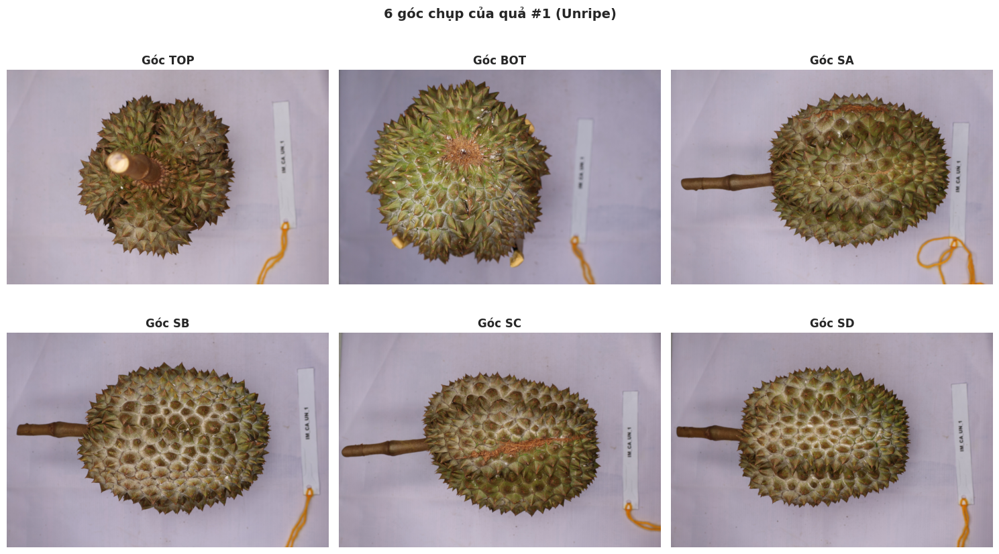

In [76]:
# 4.1. Trích xuất metadata từ tên file và hiển thị đủ 6 góc chụp của một quả
ORIENTATION_PATTERN = re.compile(r"(TOP|BOT|SA|SB|SC|SD)", re.IGNORECASE)
ID_PATTERNS = [
    re.compile(r"durian_0*(\d+)", re.IGNORECASE),
    re.compile(r"(?:^|_)(\d+)(?:_|[A-Za-z]|\.|$)"),
]
RIPENESS_PATTERN = re.compile(r"(Unripe|Overripe|Ripe)", re.IGNORECASE)
id_to_ripeness = dict(zip(df_merged["sample_id"], df_merged["Ripeness"]))


def parse_image_filename(path: str) -> Optional[Dict]:
    """Trích xuất sample_id, góc chụp và nhãn độ chín từ tên file; trả về None nếu không nhận diện được."""
    fname = os.path.basename(path)
    m_ori = ORIENTATION_PATTERN.search(fname)
    m_id = next((m for m in (p.search(fname) for p in ID_PATTERNS) if m), None)
    if not (m_ori and m_id):
        return None

    sample_id = int(m_id.group(1))
    m_rip = RIPENESS_PATTERN.search(fname)
    ripeness = m_rip.group(1).capitalize() if m_rip else id_to_ripeness.get(sample_id, "Unknown")
    return {
        "filepath": path,
        "filename": fname,
        "sample_id": sample_id,
        "orientation": m_ori.group(1).upper(),
        "ripeness": ripeness,
    }


available_images = list_images(ACTIVE_IMAGE_DIR)
parsed = [parse_image_filename(p) for p in available_images]
unmatched = [os.path.basename(p) for p, meta in zip(available_images, parsed) if meta is None]

df_img = pd.DataFrame([meta for meta in parsed if meta is not None])
df_img = df_img.merge(df_split[["sample_id", "Split"]], on="sample_id", how="left")

print(f"Nhận diện được {len(df_img)}/{len(available_images)} ảnh, thuộc {df_img['sample_id'].nunique()} quả.")
if unmatched:
    print(f"⚠️ {len(unmatched)} ảnh chưa nhận diện được góc chụp hoặc mã quả, ví dụ:")
    for name in unmatched[:10]:
        print(f"   - {name}")

print("\nSố ảnh theo góc chụp:")
display(df_img["orientation"].value_counts().reindex(ORIENTATIONS))

# Chọn quả có nhiều góc chụp nhất để hiển thị
best_id = df_img.groupby("sample_id")["orientation"].nunique().idxmax()
fruit_imgs = df_img[df_img["sample_id"] == best_id]
fruit_label = fruit_imgs["ripeness"].iloc[0]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, orientation in zip(axes.flatten(), ORIENTATIONS):
    match = fruit_imgs[fruit_imgs["orientation"] == orientation]
    if len(match):
        with Image.open(match.iloc[0]["filepath"]) as img:
            img.draft("RGB", (800, 800))  # Giải mã ở độ phân giải thấp để hiển thị nhanh
            ax.imshow(img.convert("RGB"))
        ax.set_title(f"Góc {orientation}", fontweight="bold")
    else:
        ax.text(0.5, 0.5, f"Không có ảnh góc {orientation}", ha="center", va="center", color="gray")
    ax.axis("off")
plt.suptitle(f"6 góc chụp của quả #{best_id} ({fruit_label})", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### 4.2. Độ đầy đủ góc chụp và số ảnh trên mỗi quả

Một số quả được chụp lặp lại ở nhiều phiên khác nhau. Phần này kiểm tra mỗi quả có đủ 6 góc chụp hay không và phân bố số ảnh trên từng quả, từ đó quyết định cách lấy mẫu khi huấn luyện (ví dụ cân bằng số ảnh giữa các quả).

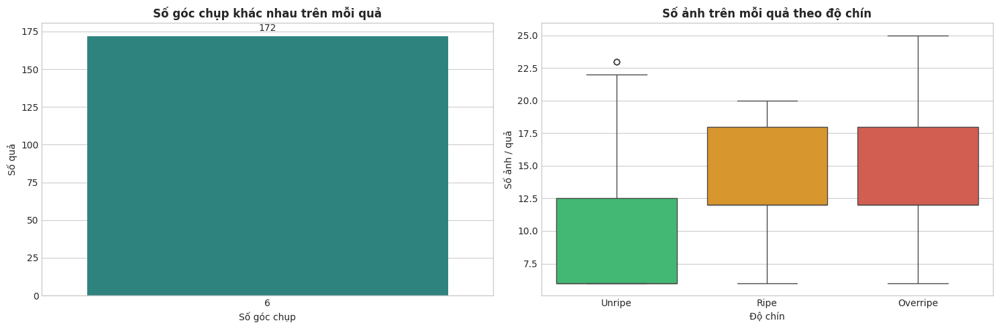

172/172 quả (100.0%) có đủ 6 góc chụp.
Trung bình 12.6 ảnh/quả (từ 6 đến 25 ảnh).


In [77]:
# 4.2. Thống kê số góc chụp và số ảnh trên từng quả
fruit_stats = df_img.groupby("sample_id").agg(
    total_images=("orientation", "count"),
    unique_orientations=("orientation", "nunique"),
    ripeness=("ripeness", "first"),
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.countplot(data=fruit_stats, x="unique_orientations", palette="viridis", ax=axes[0])
axes[0].set_title("Số góc chụp khác nhau trên mỗi quả", fontweight="bold")
axes[0].set_xlabel("Số góc chụp")
axes[0].set_ylabel("Số quả")
for bar in axes[0].patches:
    axes[0].annotate(f"{int(bar.get_height())}", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                     ha="center", va="bottom", xytext=(0, 3), textcoords="offset points")

sns.boxplot(data=fruit_stats, x="ripeness", y="total_images", order=RIPENESS_ORDER, palette=RIPENESS_PALETTE, ax=axes[1])
axes[1].set_title("Số ảnh trên mỗi quả theo độ chín", fontweight="bold")
axes[1].set_xlabel("Độ chín")
axes[1].set_ylabel("Số ảnh / quả")

plt.tight_layout()
plt.show()

num_full = (fruit_stats["unique_orientations"] == len(ORIENTATIONS)).sum()
print(f"{num_full}/{len(fruit_stats)} quả ({num_full / len(fruit_stats):.1%}) có đủ 6 góc chụp.")
print(f"Trung bình {fruit_stats['total_images'].mean():.1f} ảnh/quả "
      f"(từ {fruit_stats['total_images'].min()} đến {fruit_stats['total_images'].max()} ảnh).")

## 5. Chất lượng ảnh

### 5.1. Độ phân giải, tính toàn vẹn, độ sáng và độ tương phản

Kiểm tra trên một mẫu ngẫu nhiên tối đa 100 ảnh:
1. **Tính toàn vẹn:** phát hiện file hỏng có thể làm dừng vòng lặp huấn luyện.
2. **Kích thước và tỷ lệ khung hình:** quyết định cách resize phù hợp.
3. **Độ sáng và độ tương phản:** đánh giá mức độ chênh lệch ánh sáng giữa các ảnh, làm cơ sở chọn biên độ `ColorJitter`.

> Ảnh gốc có độ phân giải 24MP nên mỗi ảnh được giải mã ở chế độ thu nhỏ (`Image.draft`) để việc quét chỉ mất vài giây thay vì vài chục phút trên Google Drive.

Quét chất lượng ảnh:   0%|          | 0/100 [00:00<?, ?it/s]

Ảnh hợp lệ: 100 | ảnh lỗi: 0


,width,height,aspect_ratio,file_size_mb,mean_brightness,contrast
count,100.0,100.0,100.0,100.00,100.00,100.00
mean,6000.0,4000.0,1.5,7.04,139.74,47.84
std,0.0,0.0,0.0,0.95,15.18,7.94
min,6000.0,4000.0,1.5,4.52,104.90,28.72
25%,6000.0,4000.0,1.5,6.88,127.90,41.73
50%,6000.0,4000.0,1.5,7.32,142.99,49.37
75%,6000.0,4000.0,1.5,7.66,150.80,54.02
max,6000.0,4000.0,1.5,8.50,182.32,63.15


Độ sáng trung bình dao động từ 105 đến 182 (hệ số biến thiên 10.9%).


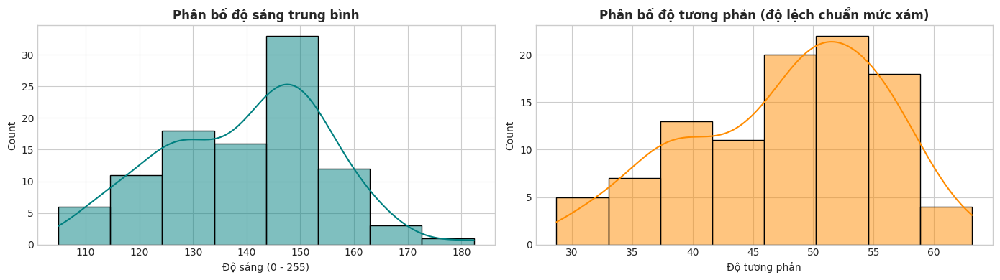

In [78]:
# 5.1. Quét chất lượng ảnh trên tập mẫu ngẫu nhiên
SAMPLE_EDA_SIZE = min(100, len(available_images))
sample_paths = random.Random(SEED).sample(available_images, SAMPLE_EDA_SIZE)

quality_records, corrupted_files = [], []
for path in tqdm(sample_paths, desc="Quét chất lượng ảnh"):
    try:
        with Image.open(path) as img:
            width, height = img.size  # Đọc từ header, chưa giải mã ảnh
            img.draft("RGB", (512, 512))
            gray = cv2.cvtColor(np.asarray(img.convert("RGB")), cv2.COLOR_RGB2GRAY)
        quality_records.append({
            "filename": os.path.basename(path),
            "width": width,
            "height": height,
            "aspect_ratio": round(width / height, 3),
            "file_size_mb": round(os.path.getsize(path) / 1024 ** 2, 2),
            "mean_brightness": round(float(gray.mean()), 2),
            "contrast": round(float(gray.std()), 2),
        })
    except Exception as exc:
        corrupted_files.append((os.path.basename(path), str(exc)))

df_quality = pd.DataFrame(quality_records)
print(f"Ảnh hợp lệ: {len(df_quality)} | ảnh lỗi: {len(corrupted_files)}")
for name, err in corrupted_files:
    print(f"   ❌ {name}: {err}")

display(df_quality.describe().round(2))

brightness = df_quality["mean_brightness"]
print(f"Độ sáng trung bình dao động từ {brightness.min():.0f} đến {brightness.max():.0f} "
      f"(hệ số biến thiên {brightness.std() / brightness.mean():.1%}).")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df_quality["mean_brightness"], kde=True, color="teal", ax=axes[0])
axes[0].set_title("Phân bố độ sáng trung bình", fontweight="bold")
axes[0].set_xlabel("Độ sáng (0 - 255)")
sns.histplot(df_quality["contrast"], kde=True, color="darkorange", ax=axes[1])
axes[1].set_title("Phân bố độ tương phản (độ lệch chuẩn mức xám)", fontweight="bold")
axes[1].set_xlabel("Độ tương phản")
plt.tight_layout()
plt.show()

### 5.2. Màu sắc vỏ quả và thống kê chuẩn hóa

1. **Sự chuyển màu khi chín:** vỏ chuyển từ xanh lục đậm (nhiều diệp lục ở quả `Unripe`) sang xanh ánh vàng hoặc vàng nâu (tích tụ carotenoid ở quả `Ripe`, `Overripe`).
2. **Kênh Hue trong không gian HSV** biểu diễn sắc độ độc lập với cường độ sáng (thang OpenCV 0 - 180: xanh lục khoảng 35 - 85, vàng cam khoảng 10 - 30). Phông nền được loại bỏ bằng ngưỡng độ bão hòa trước khi tính.
3. **Tỷ lệ Green/Red** là chỉ số đơn giản cho mức độ vàng hóa vỏ quả.
4. **Mean/Std theo kênh RGB** của dataset được so sánh với thống kê ImageNet (`mean=[0.485, 0.456, 0.406]`, `std=[0.229, 0.224, 0.225]`) để quyết định bộ tham số chuẩn hóa.

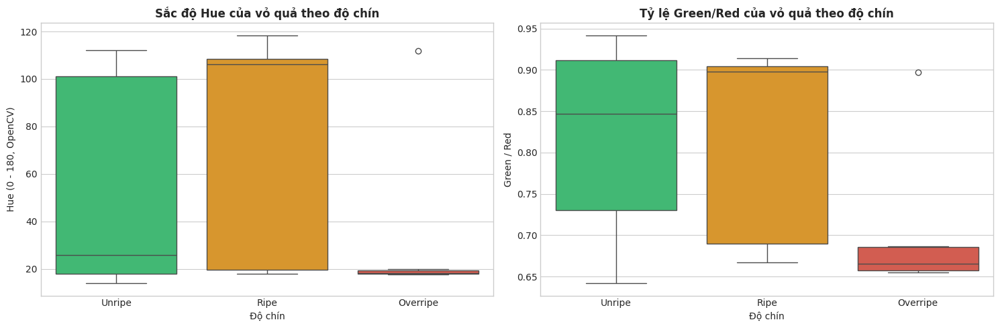

,mean_hue,green_red_ratio
ripeness,,
Unripe,25.924,0.847
Ripe,106.263,0.898
Overripe,18.287,0.665


,Dataset mean,ImageNet mean,Dataset std,ImageNet std
R,0.6079,0.485,0.1633,0.229
G,0.5361,0.456,0.1891,0.224
B,0.4949,0.406,0.2550,0.225


DATASET_MEAN = [0.6079, 0.5361, 0.4949]
DATASET_STD  = [0.1633, 0.1891, 0.255]
Nhận xét: mean của dataset lệch so với ImageNet (chênh lệch lớn nhất 0.123). Khi fine-tune mô hình pretrained vẫn nên giữ thống kê ImageNet để khớp với trọng số đã học; có thể truyền DATASET_MEAN/DATASET_STD vào tham số mean/std của VisionPreprocessor nếu huấn luyện từ đầu.


In [79]:
# 5.2. Phân tích sắc độ Hue, tỷ lệ Green/Red và tính mean/std của dataset
filename_to_ripeness = dict(zip(df_img["filename"], df_img["ripeness"]))
color_sample_paths = sample_paths[:60]

color_records, channel_means, channel_stds = [], [], []
for path in color_sample_paths:
    with Image.open(path) as img:
        img.draft("RGB", (448, 448))
        img = img.convert("RGB")
        img.thumbnail((224, 224))
        rgb = np.asarray(img)

    rgb_float = rgb / 255.0
    channel_means.append(rgb_float.mean(axis=(0, 1)))
    channel_stds.append(rgb_float.std(axis=(0, 1)))

    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    fruit_mask = hsv[:, :, 1] > 25  # Loại phông nền trắng/xám có độ bão hòa thấp
    if fruit_mask.sum() > 50:
        color_records.append({
            "ripeness": filename_to_ripeness.get(os.path.basename(path), "Unknown"),
            "mean_hue": float(hsv[:, :, 0][fruit_mask].mean()),
            "green_red_ratio": float(rgb_float[:, :, 1][fruit_mask].mean() / (rgb_float[:, :, 0][fruit_mask].mean() + 1e-6)),
        })

df_colors = pd.DataFrame(color_records)
if df_colors["ripeness"].nunique() > 1:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    sns.boxplot(data=df_colors, x="ripeness", y="mean_hue", order=RIPENESS_ORDER, palette=RIPENESS_PALETTE, ax=axes[0])
    axes[0].set_title("Sắc độ Hue của vỏ quả theo độ chín", fontweight="bold")
    axes[0].set_ylabel("Hue (0 - 180, OpenCV)")
    axes[0].set_xlabel("Độ chín")
    sns.boxplot(data=df_colors, x="ripeness", y="green_red_ratio", order=RIPENESS_ORDER, palette=RIPENESS_PALETTE, ax=axes[1])
    axes[1].set_title("Tỷ lệ Green/Red của vỏ quả theo độ chín", fontweight="bold")
    axes[1].set_ylabel("Green / Red")
    axes[1].set_xlabel("Độ chín")
    plt.tight_layout()
    plt.show()
    display(df_colors.groupby("ripeness")[["mean_hue", "green_red_ratio"]].median().reindex(RIPENESS_ORDER).round(3))

# So sánh thống kê chuẩn hóa với ImageNet
DATASET_MEAN = np.mean(channel_means, axis=0)
DATASET_STD = np.mean(channel_stds, axis=0)
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406])
IMAGENET_STD = np.array([0.229, 0.224, 0.225])

df_norm = pd.DataFrame(
    {"Dataset mean": DATASET_MEAN, "ImageNet mean": IMAGENET_MEAN, "Dataset std": DATASET_STD, "ImageNet std": IMAGENET_STD},
    index=["R", "G", "B"],
).round(4)
display(df_norm)

max_mean_gap = float(np.abs(DATASET_MEAN - IMAGENET_MEAN).max())
print(f"DATASET_MEAN = {DATASET_MEAN.round(4).tolist()}")
print(f"DATASET_STD  = {DATASET_STD.round(4).tolist()}")
if max_mean_gap < 0.05:
    print(f"Nhận xét: mean của dataset gần với ImageNet (chênh lệch lớn nhất {max_mean_gap:.3f}), dùng thống kê ImageNet là phù hợp.")
else:
    print(f"Nhận xét: mean của dataset lệch so với ImageNet (chênh lệch lớn nhất {max_mean_gap:.3f}). "
          "Khi fine-tune mô hình pretrained vẫn nên giữ thống kê ImageNet để khớp với trọng số đã học; "
          "có thể truyền DATASET_MEAN/DATASET_STD vào tham số mean/std của VisionPreprocessor nếu huấn luyện từ đầu.")

### 5.3. Độ sắc nét và mật độ cạnh gai

Vi cấu trúc rãnh gai và đĩa cuống là dấu hiệu quan trọng để nhận biết độ chín, vì vậy cần kiểm tra ảnh có bị mờ hay không:
1. **Phương sai Laplacian** $\mathrm{Var}(\nabla^2 I)$: ảnh sắc nét, nhiều gai cho giá trị cao; ảnh rung tay hoặc lệch nét cho giá trị thấp (ngưỡng tham khảo: dưới 50 xem là mờ).
2. **Mật độ cạnh Canny:** tỷ lệ phần trăm pixel thuộc cạnh, phản ánh mức độ dày đặc của gai trên ảnh.

Khảo sát 60 ảnh:
  Phương sai Laplacian trung bình: 311.39
  Mật độ cạnh trung bình         : 6.73%
  Số ảnh mờ (dưới 50)          : 0 (0.0%)


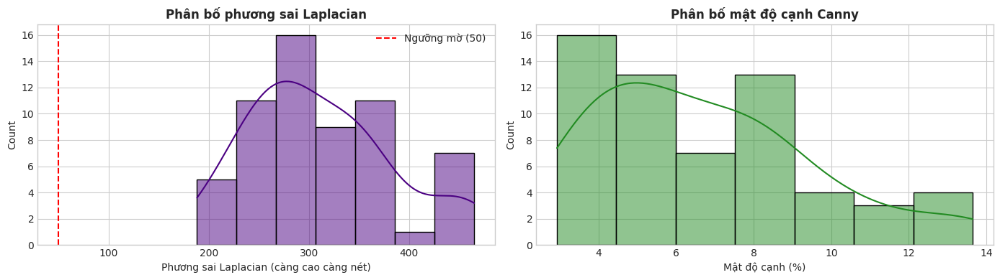

In [80]:
# 5.3. Đo độ sắc nét (phương sai Laplacian) và mật độ cạnh (Canny)
BLUR_THRESHOLD = 50.0

sharpness_records = []
for path in color_sample_paths:
    with Image.open(path) as img:
        img.draft("RGB", (600, 600))
        img = img.convert("RGB")
        img.thumbnail((300, 300))
        gray = cv2.cvtColor(np.asarray(img), cv2.COLOR_RGB2GRAY)
    lap_var = cv2.Laplacian(gray, cv2.CV_64F).var()
    sharpness_records.append({
        "filename": os.path.basename(path),
        "laplacian_variance": round(lap_var, 2),
        "edge_density_pct": round((cv2.Canny(gray, 50, 150) > 0).mean() * 100, 2),
        "is_blurry": lap_var < BLUR_THRESHOLD,
    })

df_sharpness = pd.DataFrame(sharpness_records)
blurry_count = int(df_sharpness["is_blurry"].sum())
print(f"Khảo sát {len(df_sharpness)} ảnh:")
print(f"  Phương sai Laplacian trung bình: {df_sharpness['laplacian_variance'].mean():.2f}")
print(f"  Mật độ cạnh trung bình         : {df_sharpness['edge_density_pct'].mean():.2f}%")
print(f"  Số ảnh mờ (dưới {BLUR_THRESHOLD:.0f})          : {blurry_count} ({blurry_count / len(df_sharpness):.1%})")
if blurry_count:
    display(df_sharpness[df_sharpness["is_blurry"]].sort_values("laplacian_variance"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df_sharpness["laplacian_variance"], kde=True, color="indigo", ax=axes[0])
axes[0].axvline(BLUR_THRESHOLD, color="red", linestyle="--", label=f"Ngưỡng mờ ({BLUR_THRESHOLD:.0f})")
axes[0].set_title("Phân bố phương sai Laplacian", fontweight="bold")
axes[0].set_xlabel("Phương sai Laplacian (càng cao càng nét)")
axes[0].legend()
sns.histplot(df_sharpness["edge_density_pct"], kde=True, color="forestgreen", ax=axes[1])
axes[1].set_title("Phân bố mật độ cạnh Canny", fontweight="bold")
axes[1].set_xlabel("Mật độ cạnh (%)")
plt.tight_layout()
plt.show()

## 6. Tiền xử lý và làm giàu dữ liệu

Dựa trên kết quả EDA ở phần 5, pipeline tiền xử lý được thiết kế như sau:

| Vấn đề phát hiện từ EDA | Giải pháp trong pipeline |
| :--- | :--- |
| Ảnh 6000x4000 (tỷ lệ 3:2), giải mã rất chậm | Đọc JPEG ở chế độ draft, sau đó resize theo cạnh ngắn để **giữ nguyên tỷ lệ**, cuối cùng mới crop về ảnh vuông |
| Rãnh gai và đĩa cuống là đặc trưng quan trọng | CLAHE trên kênh L (LAB) để tăng tương phản cục bộ mà không làm lệch màu vỏ |
| Độ sáng giữa các ảnh chênh lệch đáng kể | `ColorJitter` với biên độ nhỏ (hue chỉ ±0.03 để không xóa mất tín hiệu màu của độ chín) |
| Số lượng quả ít (132 quả train), dễ overfit | Crop, lật, xoay ngẫu nhiên; `RandomErasing` buộc mô hình nhìn toàn bộ bề mặt quả thay vì một vùng nhỏ |
| Ảnh gốc hầu như không mờ | `GaussianBlur` chỉ áp dụng với xác suất thấp, mô phỏng điều kiện chụp thực tế kém hơn |
| Độ chín là quá trình liên tục, ranh giới giữa các lớp không rõ | Mixup/CutMix sinh nhãn mềm, tương thích với nhãn mềm từ teacher trong bước chưng cất tri thức |

Tất cả được gom trong **một class duy nhất `VisionPreprocessor`**. Class này được định nghĩa và kiểm thử trong notebook, sau đó sao chép nguyên vẹn sang `preprocess_vision.py`.

### 6.1. Định nghĩa class `VisionPreprocessor`

Ba mức tăng cường dữ liệu cho tập train:

| Thành phần | `light` | `medium` (mặc định) | `strong` |
| :--- | :---: | :---: | :---: |
| RandomResizedCrop scale | 0.85 - 1.0 | 0.8 - 1.0 | 0.7 - 1.0 |
| RandomRotation | ±10° | ±15° | ±20° |
| ColorJitter | Không | Có | Có (mạnh hơn) |
| GaussianBlur (xác suất) | 0 | 0.2 | 0.3 |
| RandomPerspective (xác suất) | 0 | 0 | 0.3 |
| RandomErasing (xác suất) | 0 | 0.2 | 0.3 |

Gợi ý: dùng `light` cho mô hình nhỏ hoặc khi mới bắt đầu thử nghiệm, `medium` cho đa số trường hợp, `strong` cho mô hình lớn (ViT, Swin) dễ overfit.

In [81]:
# 6.1. Định nghĩa class VisionPreprocessor (được sao chép nguyên vẹn sang preprocess_vision.py)
class VisionPreprocessor:
    """Bộ tiền xử lý và làm giàu dữ liệu ảnh RGB quả sầu riêng.

    Class cung cấp:
    - `get_train_transforms()` / `get_val_transforms()`: pipeline torchvision dùng cho Dataset.
    - `load_image()`: đọc ảnh từ đường dẫn, numpy array hoặc PIL Image.
    - `preprocess_image()`: tiền xử lý một ảnh đơn lẻ thành tensor (C, H, W).
    - `apply_clahe()`: áp dụng riêng CLAHE để trực quan hóa.
    - `denormalize()`: đưa tensor đã chuẩn hóa về ảnh uint8 để hiển thị.
    - `mix_batch()`: Mixup / CutMix ở cấp độ batch, trả về nhãn mềm.
    """

    IMAGENET_MEAN = (0.485, 0.456, 0.406)
    IMAGENET_STD = (0.229, 0.224, 0.225)

    # Cấu hình cho từng mức tăng cường dữ liệu.
    # color_jitter = (brightness, contrast, saturation, hue); None nghĩa là tắt.
    POLICY_CONFIGS: Dict[str, Dict] = {
        "light": {
            "crop_scale": (0.85, 1.0),
            "rotation": 10,
            "color_jitter": None,
            "blur_prob": 0.0,
            "perspective_prob": 0.0,
            "erasing_prob": 0.0,
        },
        "medium": {
            "crop_scale": (0.8, 1.0),
            "rotation": 15,
            "color_jitter": (0.15, 0.15, 0.15, 0.03),
            "blur_prob": 0.2,
            "perspective_prob": 0.0,
            "erasing_prob": 0.2,
        },
        "strong": {
            "crop_scale": (0.7, 1.0),
            "rotation": 20,
            "color_jitter": (0.2, 0.2, 0.2, 0.04),
            "blur_prob": 0.3,
            "perspective_prob": 0.3,
            "erasing_prob": 0.3,
        },
    }

    class ClaheTransform:
        """Transform áp dụng CLAHE lên kênh L của không gian màu LAB.

        Chỉ can thiệp vào kênh độ sáng L nên làm nổi bật rãnh gai và đĩa cuống
        mà không làm lệch màu vỏ quả (kênh A, B được giữ nguyên).
        Được khai báo dạng class lồng nhau (thay vì lambda) để có thể pickle
        khi DataLoader dùng nhiều worker.
        """

        def __init__(self, clip_limit: float = 2.0, tile_grid_size: Tuple[int, int] = (8, 8)):
            self.clip_limit = clip_limit
            self.tile_grid_size = tuple(tile_grid_size)

        def __call__(self, img: Union[Image.Image, np.ndarray]) -> Image.Image:
            """Nhận ảnh PIL hoặc numpy RGB, trả về ảnh PIL RGB đã cân bằng sáng."""
            rgb = np.asarray(img.convert("RGB")) if isinstance(img, Image.Image) else img
            l_channel, a_channel, b_channel = cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))
            clahe = cv2.createCLAHE(clipLimit=self.clip_limit, tileGridSize=self.tile_grid_size)
            lab = cv2.merge((clahe.apply(l_channel), a_channel, b_channel))
            return Image.fromarray(cv2.cvtColor(lab, cv2.COLOR_LAB2RGB))

        def __repr__(self) -> str:
            return f"ClaheTransform(clip_limit={self.clip_limit}, tile_grid_size={self.tile_grid_size})"

    def __init__(
        self,
        image_size: Union[int, Tuple[int, int]] = 224,
        use_clahe: bool = True,
        clahe_clip_limit: float = 2.0,
        clahe_tile_grid_size: Tuple[int, int] = (8, 8),
        aug_policy: str = "medium",
        resize_ratio: float = 1.14,
        mean: Optional[Sequence[float]] = None,
        std: Optional[Sequence[float]] = None,
        num_classes: int = 3,
        mixup_alpha: float = 0.8,
        cutmix_alpha: float = 1.0,
        mix_prob: float = 1.0,
    ):
        """Khởi tạo bộ tiền xử lý.

        Args:
            image_size: Kích thước ảnh đầu ra, nhận int (ảnh vuông) hoặc tuple (H, W).
            use_clahe: Bật/tắt bước cân bằng sáng CLAHE.
            clahe_clip_limit: Ngưỡng giới hạn tương phản của CLAHE.
            clahe_tile_grid_size: Kích thước lưới chia ô của CLAHE.
            aug_policy: Mức tăng cường dữ liệu cho tập train: "light", "medium" hoặc "strong".
            resize_ratio: Tỷ lệ giữa cạnh ngắn sau resize và kích thước crop (mặc định 1.14 ~ 256/224).
            mean: Trung bình chuẩn hóa theo kênh RGB, mặc định dùng thống kê ImageNet.
            std: Độ lệch chuẩn chuẩn hóa theo kênh RGB, mặc định dùng thống kê ImageNet.
            num_classes: Số lớp độ chín, dùng khi tạo nhãn mềm.
            mixup_alpha: Tham số phân phối Beta của Mixup (0 để tắt Mixup).
            cutmix_alpha: Tham số phân phối Beta của CutMix (0 để tắt CutMix).
            mix_prob: Xác suất áp dụng Mixup/CutMix cho mỗi batch.
        """
        policy = aug_policy.lower()
        if policy not in self.POLICY_CONFIGS:
            raise ValueError(f"aug_policy phải thuộc {list(self.POLICY_CONFIGS)}, nhận được: '{aug_policy}'")

        self.image_size = (image_size, image_size) if isinstance(image_size, int) else tuple(image_size)
        self.resize_size = int(round(min(self.image_size) * resize_ratio))
        self.use_clahe = use_clahe
        self.aug_policy = policy
        self.mean = tuple(mean) if mean is not None else self.IMAGENET_MEAN
        self.std = tuple(std) if std is not None else self.IMAGENET_STD

        self.num_classes = num_classes
        self.mixup_alpha = mixup_alpha
        self.cutmix_alpha = cutmix_alpha
        self.mix_prob = mix_prob

        self.clahe = self.ClaheTransform(clahe_clip_limit, clahe_tile_grid_size)
        self.train_transforms = self._build_train_transforms()
        self.val_transforms = self._build_val_transforms()

    # ------------------------------------------------------------------
    # Pipeline transforms
    # ------------------------------------------------------------------
    def _build_common_head(self) -> list:
        """Các bước đầu chung cho cả train và val: resize giữ tỷ lệ, sau đó CLAHE.

        Resize theo cạnh ngắn (truyền vào một số nguyên) nên ảnh 6000x4000 trở thành
        khoảng 382x256, không bị bóp méo. CLAHE đặt sau resize để chạy nhanh trên ảnh nhỏ.
        """
        head = [transforms.Resize(self.resize_size, interpolation=transforms.InterpolationMode.BILINEAR)]
        if self.use_clahe:
            head.append(self.clahe)
        return head

    def _build_normalize_tail(self) -> list:
        """Các bước cuối chung: chuyển sang tensor và chuẩn hóa theo mean/std."""
        return [transforms.ToTensor(), transforms.Normalize(mean=self.mean, std=self.std)]

    def _build_train_transforms(self) -> transforms.Compose:
        """Xây dựng pipeline tăng cường dữ liệu cho tập train theo `aug_policy`."""
        cfg = self.POLICY_CONFIGS[self.aug_policy]
        steps = self._build_common_head()

        if cfg["perspective_prob"] > 0:
            steps.append(transforms.RandomPerspective(distortion_scale=0.15, p=cfg["perspective_prob"]))

        steps += [
            transforms.RandomResizedCrop(
                self.image_size,
                scale=cfg["crop_scale"],
                ratio=(0.85, 1.15),
                interpolation=transforms.InterpolationMode.BILINEAR,
            ),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomRotation(degrees=cfg["rotation"]),
        ]

        if cfg["color_jitter"] is not None:
            brightness, contrast, saturation, hue = cfg["color_jitter"]
            steps.append(transforms.ColorJitter(brightness, contrast, saturation, hue))

        if cfg["blur_prob"] > 0:
            steps.append(
                transforms.RandomApply([transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.2))], p=cfg["blur_prob"])
            )

        steps += self._build_normalize_tail()

        if cfg["erasing_prob"] > 0:
            steps.append(
                transforms.RandomErasing(p=cfg["erasing_prob"], scale=(0.02, 0.2), ratio=(0.3, 3.3), value="random")
            )

        return transforms.Compose(steps)

    def _build_val_transforms(self) -> transforms.Compose:
        """Xây dựng pipeline cố định (không ngẫu nhiên) cho tập val/test: resize giữ tỷ lệ rồi center crop."""
        steps = self._build_common_head()
        steps.append(transforms.CenterCrop(self.image_size))
        steps += self._build_normalize_tail()
        return transforms.Compose(steps)

    def get_train_transforms(self) -> transforms.Compose:
        """Trả về pipeline transforms cho tập train."""
        return self.train_transforms

    def get_val_transforms(self) -> transforms.Compose:
        """Trả về pipeline transforms cho tập val/test."""
        return self.val_transforms

    # ------------------------------------------------------------------
    # Xử lý ảnh đơn lẻ
    # ------------------------------------------------------------------
    def load_image(self, image_input: Union[str, Image.Image, np.ndarray]) -> Image.Image:
        """Đọc ảnh và trả về PIL Image RGB.

        Với file JPEG, dùng `Image.draft` để giải mã trực tiếp ở độ phân giải thấp hơn
        (vẫn lớn hơn kích thước resize), giúp đọc ảnh 24MP nhanh hơn nhiều lần.
        """
        if isinstance(image_input, str):
            if not os.path.exists(image_input):
                raise FileNotFoundError(f"Không tìm thấy file ảnh: {image_input}")
            img = Image.open(image_input)
            draft_size = self.resize_size * 2
            img.draft("RGB", (draft_size, draft_size))
            return img.convert("RGB")
        if isinstance(image_input, np.ndarray):
            return Image.fromarray(image_input).convert("RGB")
        if isinstance(image_input, Image.Image):
            return image_input.convert("RGB")
        raise TypeError(f"Định dạng ảnh không được hỗ trợ: {type(image_input)}")

    def preprocess_image(
        self,
        image_input: Union[str, Image.Image, np.ndarray],
        is_train: bool = False,
    ) -> torch.Tensor:
        """Tiền xử lý một ảnh đơn lẻ, trả về tensor (C, H, W) đã chuẩn hóa."""
        pipeline = self.train_transforms if is_train else self.val_transforms
        return pipeline(self.load_image(image_input))

    def apply_clahe(self, img: Union[Image.Image, np.ndarray]) -> Image.Image:
        """Áp dụng riêng bước CLAHE lên ảnh, dùng cho mục đích trực quan hóa."""
        return self.clahe(img)

    def denormalize(self, tensor: torch.Tensor) -> np.ndarray:
        """Chuyển tensor đã chuẩn hóa (C, H, W) hoặc (1, C, H, W) về ảnh numpy RGB uint8."""
        if tensor.dim() == 4:
            tensor = tensor.squeeze(0)
        mean = torch.tensor(self.mean).view(3, 1, 1)
        std = torch.tensor(self.std).view(3, 1, 1)
        img = (tensor.detach().cpu() * std + mean).clamp(0.0, 1.0)
        return (img.permute(1, 2, 0).numpy() * 255).astype(np.uint8)

    # ------------------------------------------------------------------
    # Mixup / CutMix cấp độ batch
    # ------------------------------------------------------------------
    def mix_batch(self, images: torch.Tensor, labels: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        """Áp dụng Mixup hoặc CutMix (chọn ngẫu nhiên 50/50) lên một batch.

        Args:
            images: Tensor ảnh (B, C, H, W) đã qua train transforms.
            labels: Nhãn dạng chỉ số (B,) hoặc nhãn mềm (B, num_classes), ví dụ xác suất từ teacher.

        Returns:
            Tuple (ảnh đã trộn, nhãn mềm kích thước (B, num_classes)).
        """
        targets = self._to_soft_targets(labels)
        mixup_on, cutmix_on = self.mixup_alpha > 0, self.cutmix_alpha > 0
        if (not mixup_on and not cutmix_on) or torch.rand(1).item() > self.mix_prob:
            return images, targets

        perm = torch.randperm(images.size(0), device=images.device)
        use_cutmix = cutmix_on and (not mixup_on or torch.rand(1).item() < 0.5)

        if use_cutmix:
            lam = float(np.random.beta(self.cutmix_alpha, self.cutmix_alpha))
            y1, x1, y2, x2 = self._random_bbox(images.shape[2], images.shape[3], lam)
            images = images.clone()
            images[:, :, y1:y2, x1:x2] = images[perm, :, y1:y2, x1:x2]
            # Tính lại lambda theo diện tích thực tế sau khi bbox bị cắt ở biên ảnh
            lam = 1.0 - (y2 - y1) * (x2 - x1) / (images.shape[2] * images.shape[3])
        else:
            lam = float(np.random.beta(self.mixup_alpha, self.mixup_alpha))
            images = lam * images + (1.0 - lam) * images[perm]

        return images, lam * targets + (1.0 - lam) * targets[perm]

    def _to_soft_targets(self, labels: torch.Tensor) -> torch.Tensor:
        """Chuyển nhãn chỉ số sang one-hot; nếu đã là nhãn mềm thì giữ nguyên."""
        if labels.dim() == 2:
            return labels.float()
        return torch.nn.functional.one_hot(labels.long(), self.num_classes).float()

    @staticmethod
    def _random_bbox(height: int, width: int, lam: float) -> Tuple[int, int, int, int]:
        """Sinh hộp cắt ngẫu nhiên cho CutMix, diện tích xấp xỉ (1 - lam) diện tích ảnh.

        Returns:
            Tuple (y1, x1, y2, x2) đã được giới hạn trong biên ảnh.
        """
        cut_ratio = np.sqrt(1.0 - lam)
        cut_h, cut_w = int(height * cut_ratio), int(width * cut_ratio)
        cy, cx = np.random.randint(height), np.random.randint(width)
        y1, y2 = np.clip([cy - cut_h // 2, cy + cut_h // 2], 0, height)
        x1, x2 = np.clip([cx - cut_w // 2, cx + cut_w // 2], 0, width)
        return int(y1), int(x1), int(y2), int(x2)


preprocessor = VisionPreprocessor(image_size=224, use_clahe=True, aug_policy="medium")
print("Pipeline train:")
print(preprocessor.get_train_transforms())
print("\nPipeline val/test:")
print(preprocessor.get_val_transforms())

Pipeline train:
Compose(
    Resize(size=255, interpolation=bilinear, max_size=None, antialias=True)
    ClaheTransform(clip_limit=2.0, tile_grid_size=(8, 8))
    RandomResizedCrop(size=(224, 224), scale=(0.8, 1.0), ratio=(0.85, 1.15), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.85, 1.15), contrast=(0.85, 1.15), saturation=(0.85, 1.15), hue=(-0.03, 0.03))
    RandomApply(
    p=0.2
    GaussianBlur(kernel_size=(3, 3), sigma=(0.1, 1.2))
)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
    RandomErasing(p=0.2, scale=(0.02, 0.2), ratio=(0.3, 3.3), value=random, inplace=False)
)

Pipeline val/test:
Compose(
    Resize(size=255, interpolation=bilinear, max_size=None, antialias=True)
    ClaheTransform(clip_limit=2.0, tile_grid_size=(8, 8))
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=(0.485,

### 6.2. Kiểm chứng CLAHE trên kênh L

Theo đặc tả đề tài (mục 1.3.1), CLAHE được dùng để làm nổi bật kết cấu rãnh gai và vùng cuống.
- Nếu cân bằng sáng trực tiếp trên RGB, tỷ lệ giữa 3 kênh màu bị thay đổi và màu vỏ bị lệch.
- Trong không gian **CIE LAB**, kênh L chứa độ sáng và chi tiết bề mặt, còn kênh A, B chứa màu. Chỉ áp dụng CLAHE lên kênh L giúp tăng chi tiết gai mà vẫn giữ màu vỏ.

Cell dưới đây so sánh trực quan và định lượng: độ tương phản kênh L tăng bao nhiêu, kênh màu A, B thay đổi bao nhiêu.

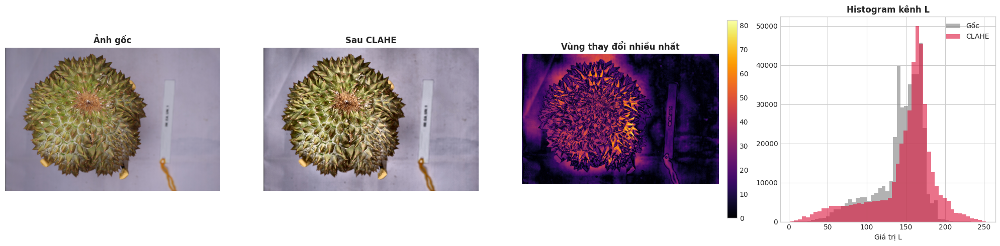

Độ lệch chuẩn kênh L: 30.67 -> 40.63 (+32.5%)
Thay đổi trung bình của kênh màu A, B: 0.07 (thang 0 - 255), màu vỏ gần như được giữ nguyên.


In [82]:
# 6.2. So sánh ảnh trước và sau CLAHE
sample_img_path = df_img["filepath"].iloc[0]
orig_img = preprocessor.load_image(sample_img_path)
orig_img.thumbnail((800, 800))
clahe_img = preprocessor.apply_clahe(orig_img)

np_orig, np_clahe = np.asarray(orig_img), np.asarray(clahe_img)
lab_orig = cv2.cvtColor(np_orig, cv2.COLOR_RGB2LAB).astype(np.float32)
lab_clahe = cv2.cvtColor(np_clahe, cv2.COLOR_RGB2LAB).astype(np.float32)
diff_gray = cv2.cvtColor(cv2.absdiff(np_orig, np_clahe), cv2.COLOR_RGB2GRAY)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(orig_img)
axes[0].set_title("Ảnh gốc", fontweight="bold")
axes[1].imshow(clahe_img)
axes[1].set_title("Sau CLAHE", fontweight="bold")
heat = axes[2].imshow(diff_gray, cmap="inferno")
axes[2].set_title("Vùng thay đổi nhiều nhất", fontweight="bold")
fig.colorbar(heat, ax=axes[2], fraction=0.046, pad=0.04)
for ax in axes[:3]:
    ax.axis("off")
axes[3].hist(lab_orig[:, :, 0].ravel(), bins=50, color="gray", alpha=0.6, label="Gốc")
axes[3].hist(lab_clahe[:, :, 0].ravel(), bins=50, color="crimson", alpha=0.6, label="CLAHE")
axes[3].set_title("Histogram kênh L", fontweight="bold")
axes[3].set_xlabel("Giá trị L")
axes[3].legend()
plt.tight_layout()
plt.show()

l_std_before, l_std_after = lab_orig[:, :, 0].std(), lab_clahe[:, :, 0].std()
ab_shift = np.abs(lab_clahe[:, :, 1:] - lab_orig[:, :, 1:]).mean()
print(f"Độ lệch chuẩn kênh L: {l_std_before:.2f} -> {l_std_after:.2f} ({(l_std_after / l_std_before - 1):+.1%})")
print(f"Thay đổi trung bình của kênh màu A, B: {ab_shift:.2f} (thang 0 - 255), màu vỏ gần như được giữ nguyên.")

### 6.3. Kiểm chứng pipeline augmentation theo từng mức

Mỗi hàng ứng với một mức `aug_policy`. Cột đầu tiên là ảnh qua pipeline val/test (resize giữ tỷ lệ + center crop), các cột còn lại là các lần biến đổi ngẫu nhiên của pipeline train. Cần kiểm tra bằng mắt rằng ảnh sau biến đổi vẫn giữ được hình dạng quả, màu vỏ và kết cấu gai.

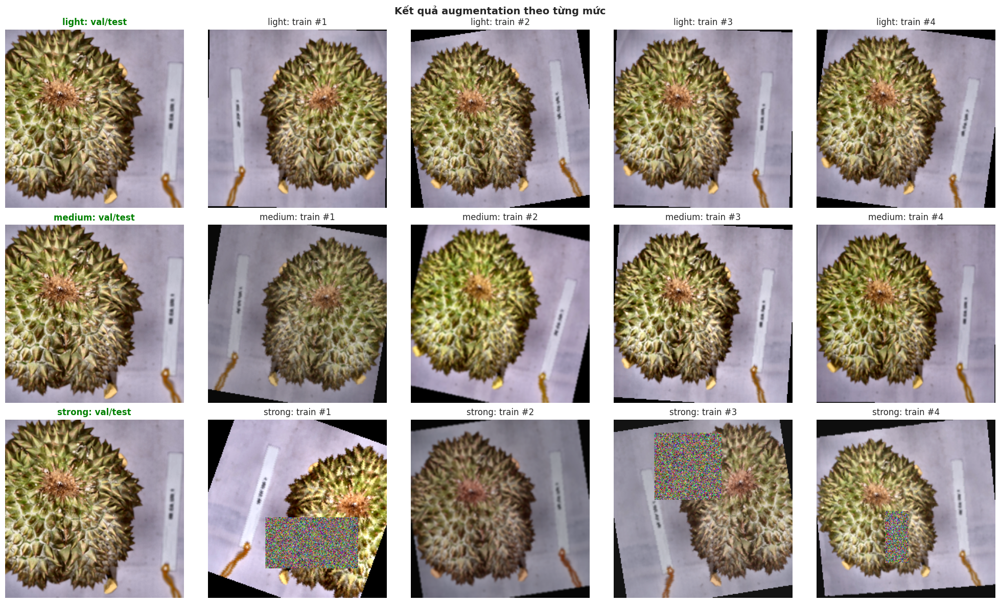

In [83]:
# 6.3. Trực quan hóa augmentation của 3 mức light, medium, strong
NUM_AUG_SAMPLES = 4
policies = list(VisionPreprocessor.POLICY_CONFIGS)

fig, axes = plt.subplots(len(policies), NUM_AUG_SAMPLES + 1, figsize=(4 * (NUM_AUG_SAMPLES + 1), 4 * len(policies)))
for row, policy in enumerate(policies):
    policy_preprocessor = VisionPreprocessor(image_size=224, use_clahe=True, aug_policy=policy)
    axes[row, 0].imshow(policy_preprocessor.denormalize(policy_preprocessor.preprocess_image(orig_img, is_train=False)))
    axes[row, 0].set_title(f"{policy}: val/test", fontweight="bold", color="green")
    for col in range(1, NUM_AUG_SAMPLES + 1):
        aug_tensor = policy_preprocessor.preprocess_image(orig_img, is_train=True)
        axes[row, col].imshow(policy_preprocessor.denormalize(aug_tensor))
        axes[row, col].set_title(f"{policy}: train #{col}")
    for ax in axes[row]:
        ax.axis("off")

plt.suptitle("Kết quả augmentation theo từng mức", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### 6.4. Kiểm chứng Mixup và CutMix

Quá trình chín (`Unripe` → `Ripe` → `Overripe`) là một phổ liên tục, nên nhãn one-hot cứng (ví dụ `[1, 0, 0]`) dễ khiến mô hình quá tự tin ở vùng ranh giới giữa các lớp.

- **Mixup:** trộn tuyến tính hai ảnh và nhãn với $\lambda \sim \mathrm{Beta}(\alpha, \alpha)$:
  $$\tilde{x} = \lambda x_i + (1 - \lambda) x_j, \qquad \tilde{y} = \lambda y_i + (1 - \lambda) y_j$$
- **CutMix:** cắt một vùng của ảnh $x_j$ dán vào ảnh $x_i$, nhãn được trộn theo tỷ lệ diện tích vùng cắt.

Cả hai đều sinh ra **nhãn mềm**, cùng dạng với phân phối xác suất do teacher tạo ra trong bước chưng cất tri thức. Hàm `mix_batch()` nhận cả nhãn chỉ số lẫn nhãn mềm, nên có thể áp dụng trực tiếp lên soft target của teacher. Mixup/CutMix chỉ dùng trong vòng lặp huấn luyện, không dùng cho val/test.

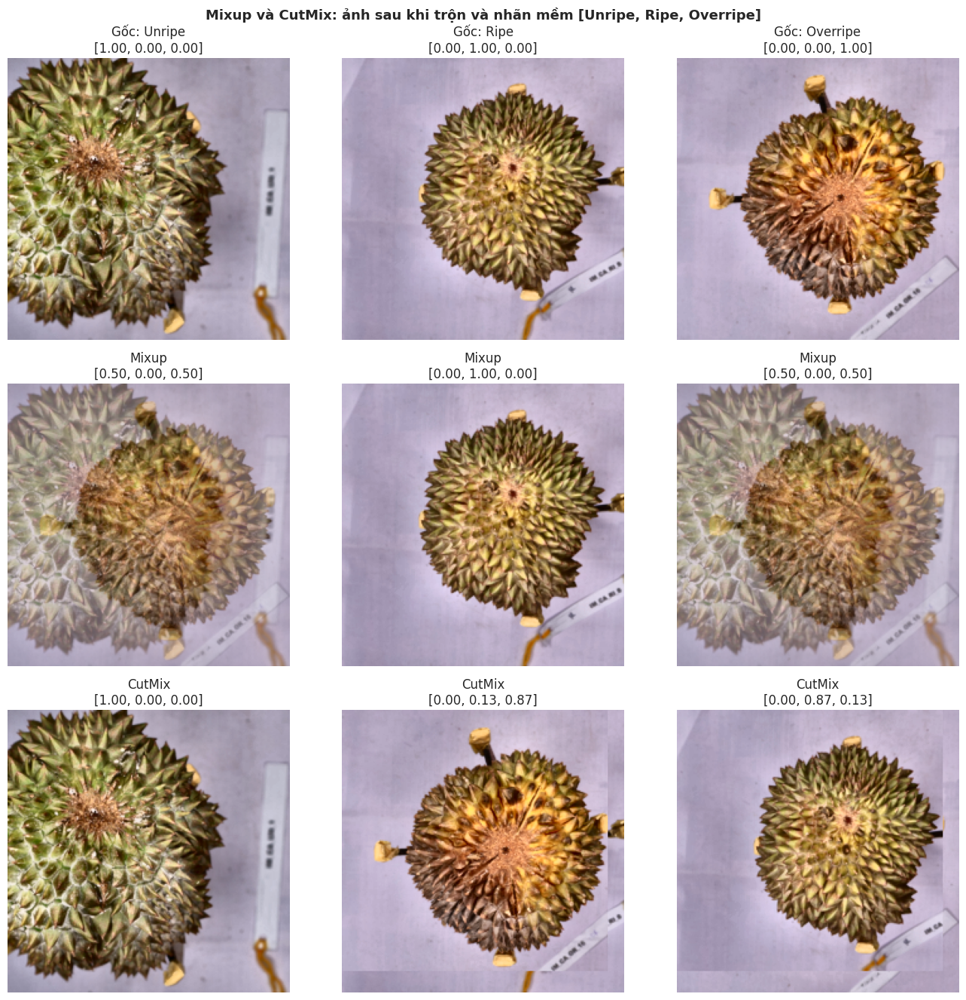

In [84]:
# 6.4. Trực quan hóa Mixup và CutMix trên một batch gồm đủ 3 nhãn độ chín
demo_rows = (
    df_img[df_img["ripeness"].isin(RIPENESS_ORDER)]
    .groupby("ripeness", group_keys=False)
    .head(1)
    .sort_values("ripeness", key=lambda s: s.map(LABEL_TO_IDX))
)
demo_images = torch.stack([preprocessor.preprocess_image(p, is_train=False) for p in demo_rows["filepath"]])
demo_labels = torch.tensor([LABEL_TO_IDX[r] for r in demo_rows["ripeness"]])

mixers = {
    "Mixup": VisionPreprocessor(image_size=224, mixup_alpha=0.8, cutmix_alpha=0.0),
    "CutMix": VisionPreprocessor(image_size=224, mixup_alpha=0.0, cutmix_alpha=1.0),
}


def format_target(target: torch.Tensor) -> str:
    """Định dạng nhãn mềm thành chuỗi ngắn gọn để hiển thị trên tiêu đề ảnh."""
    return "[" + ", ".join(f"{v:.2f}" for v in target.tolist()) + "]"


torch.manual_seed(SEED)
np.random.seed(SEED)
n_cols = len(demo_labels)
fig, axes = plt.subplots(1 + len(mixers), n_cols, figsize=(4.5 * n_cols, 4.5 * (1 + len(mixers))), squeeze=False)

for col in range(n_cols):
    axes[0, col].imshow(preprocessor.denormalize(demo_images[col]))
    axes[0, col].set_title(f"Gốc: {IDX_TO_LABEL[demo_labels[col].item()]}\n{format_target(preprocessor._to_soft_targets(demo_labels)[col])}")

for row, (name, mixer) in enumerate(mixers.items(), start=1):
    mixed_images, soft_targets = mixer.mix_batch(demo_images, demo_labels)
    for col in range(n_cols):
        axes[row, col].imshow(preprocessor.denormalize(mixed_images[col]))
        axes[row, col].set_title(f"{name}\n{format_target(soft_targets[col])}")

for ax in axes.flatten():
    ax.axis("off")
plt.suptitle("Mixup và CutMix: ảnh sau khi trộn và nhãn mềm [Unripe, Ripe, Overripe]", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 7. Đóng gói PyTorch Dataset và DataLoader

Class `DurianVisionDataset` dùng cho các bước tiếp theo:
- `02_train_unimodal_vision`: huấn luyện baseline chỉ dùng ảnh.
- `03_create_final_dataset` và `04_train_teacher_and_student`: hợp nhất đa phương thức và chưng cất tri thức.

Dataset nhận bảng metadata `df_img` đã tạo ở phần 4, lọc theo tập (`train`, `val`, `test`), bỏ qua ảnh không xác định được nhãn và trả về `(image_tensor, label, sample_id, orientation)`. Cell cuối cũng minh họa cách gọi `mix_batch()` trong một bước huấn luyện.

Tập train:  1552 ảnh (bỏ qua 0 ảnh không có nhãn)
Tập val  :   308 ảnh (bỏ qua 0 ảnh không có nhãn)
Tập test :   302 ảnh (bỏ qua 0 ảnh không có nhãn)

Kích thước batch ảnh: (8, 3, 224, 224) (B, C, H, W)
Kích thước batch nhãn: (8,)
Sau mix_batch: ảnh (8, 3, 224, 224), nhãn mềm (8, 3)
Tổng xác suất mỗi nhãn mềm: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


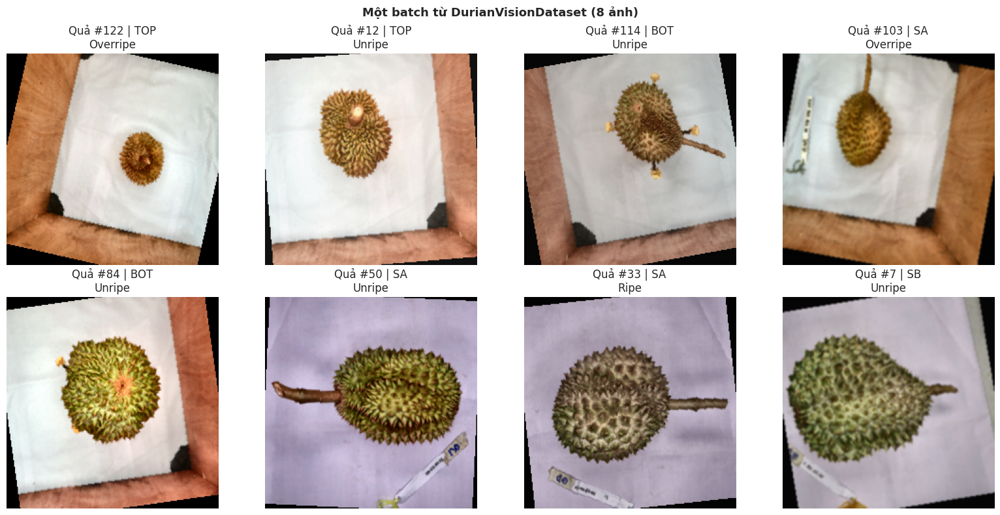

In [85]:
# 7.1. Định nghĩa DurianVisionDataset và kiểm thử nạp một batch
class DurianVisionDataset(Dataset):
    """Dataset ảnh RGB quả sầu riêng cho nhánh thị giác.

    Args:
        metadata: DataFrame có các cột filepath, sample_id, orientation, ripeness (và Split nếu lọc theo tập).
        preprocessor: Đối tượng VisionPreprocessor dùng để biến đổi ảnh.
        split: Tên tập cần lấy ("train", "val", "test"); None để lấy toàn bộ.
        is_train: True để dùng pipeline augmentation, False để dùng pipeline val/test.
    """

    def __init__(self, metadata: pd.DataFrame, preprocessor: VisionPreprocessor,
                 split: Optional[str] = None, is_train: bool = False):
        df = metadata if split is None else metadata[metadata["Split"] == split]
        known = df["ripeness"].isin(LABEL_TO_IDX)
        self.num_skipped = int((~known).sum())
        self.samples = [
            (row.filepath, LABEL_TO_IDX[row.ripeness], int(row.sample_id), row.orientation)
            for row in df[known].itertuples()
        ]
        self.preprocessor = preprocessor
        self.is_train = is_train

    def __len__(self) -> int:
        return len(self.samples)

    def __getitem__(self, idx: int):
        path, label, sample_id, orientation = self.samples[idx]
        image = self.preprocessor.preprocess_image(path, is_train=self.is_train)
        return image, torch.tensor(label, dtype=torch.long), sample_id, orientation


has_split = df_img["Split"].notna().any()
for split_name in ["train", "val", "test"]:
    ds = DurianVisionDataset(df_img, preprocessor, split=split_name if has_split else None)
    print(f"Tập {split_name:<5}: {len(ds):>5} ảnh (bỏ qua {ds.num_skipped} ảnh không có nhãn)")

train_dataset = DurianVisionDataset(df_img, preprocessor, split="train" if has_split else None, is_train=True)
batch_size = min(8, len(train_dataset))
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)

batch_images, batch_labels, batch_ids, batch_oris = next(iter(train_loader))
print(f"\nKích thước batch ảnh: {tuple(batch_images.shape)} (B, C, H, W)")
print(f"Kích thước batch nhãn: {tuple(batch_labels.shape)}")

# Minh họa một bước huấn luyện: áp dụng Mixup/CutMix lên batch vừa nạp
mixed_images, soft_targets = preprocessor.mix_batch(batch_images, batch_labels)
print(f"Sau mix_batch: ảnh {tuple(mixed_images.shape)}, nhãn mềm {tuple(soft_targets.shape)}")
print(f"Tổng xác suất mỗi nhãn mềm: {soft_targets.sum(dim=1).tolist()}")

cols = 4
rows = (batch_size + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows), squeeze=False)
for i, ax in enumerate(axes.flatten()):
    ax.axis("off")
    if i < batch_size:
        ax.imshow(preprocessor.denormalize(batch_images[i]))
        ax.set_title(f"Quả #{batch_ids[i].item()} | {batch_oris[i]}\n{IDX_TO_LABEL[batch_labels[i].item()]}")
plt.suptitle(f"Một batch từ DurianVisionDataset ({batch_size} ảnh)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 8. Kết luận và bàn giao

### Kết quả EDA (theo lần chạy với dữ liệu thật trên Colab)
- **Nhãn và phân chia:** 189 quả cân bằng tuyệt đối 63/63/63; chia theo cấp độ quả thành 132 train, 28 val, 29 test, không rò rỉ giữa các tập.
- **Chỉ số lý hóa:** độ cứng giảm mạnh và TSS tăng rõ khi quả chuyển từ `Unripe` sang `Ripe`/`Overripe`, khẳng định nhãn độ chín có cơ sở sinh lý rõ ràng.
- **Ảnh:** 2.718 ảnh, toàn bộ 6000x4000 (tỷ lệ 3:2), không phát hiện file hỏng trong mẫu khảo sát; độ sáng dao động khá rộng (khoảng 109 - 188); ảnh rất nét (phương sai Laplacian trung bình khoảng 274, không có ảnh mờ).
- **Màu sắc:** mean RGB của dataset cao hơn ImageNet khoảng 0.07 - 0.12 ở mỗi kênh; vẫn giữ thống kê ImageNet khi fine-tune mô hình pretrained.
- **Cần xử lý thêm:** chỉ 2.162/2.718 ảnh nhận diện được góc chụp từ tên file (tương ứng 172/189 quả). Cần xem danh sách tên file chưa nhận diện ở mục 4.1 để bổ sung quy tắc trích xuất, tránh mất khoảng 20% dữ liệu ảnh khi huấn luyện.

### Pipeline tiền xử lý đã kiểm chứng
1. Đọc JPEG ở chế độ draft, resize theo cạnh ngắn (giữ tỷ lệ 3:2).
2. CLAHE trên kênh L của không gian LAB.
3. Augmentation cho tập train theo 3 mức `light` / `medium` / `strong`; tập val/test chỉ center crop.
4. Chuẩn hóa theo thống kê ImageNet (có thể thay qua tham số `mean`, `std`).
5. Mixup/CutMix ở cấp độ batch qua `mix_batch()`, hỗ trợ cả nhãn chỉ số và nhãn mềm từ teacher.

### Bàn giao
Class `VisionPreprocessor` ở mục 6.1 đã được sao chép nguyên vẹn sang [preprocess_vision.py](preprocess_vision.py). Các notebook phía sau sử dụng như sau:

```python
from preprocess_vision import VisionPreprocessor

preprocessor = VisionPreprocessor(image_size=224, aug_policy="medium")
train_tf = preprocessor.get_train_transforms()
val_tf = preprocessor.get_val_transforms()

for images, labels in train_loader:
    images, soft_targets = preprocessor.mix_batch(images, labels)
    ...
```